MD# 05 · LightGBM and SHAP explanations

**Northvale Credit is a fictional lender; the data is public Lending Club loans.**

Question: does a gradient-boosted model find risk that the grade misses, and can its decisions be explained applicant by applicant? Training is in `src/northvale/models.py`, explanations in `src/northvale/explain.py`.

In [1]:
import json
import warnings

import pandas as pd
from IPython.display import Image, display

from northvale import config as C

warnings.filterwarnings("ignore")
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
pd.set_option("display.max_columns", 20)
m = json.loads(C.METRICS.read_text())


def fig(name, width=900):
    display(Image(filename=str(C.FIGURES / f"{name}.png"), width=width))

MD## 1. Small search with early stopping on validation

In [2]:
pd.read_csv(C.TABLES / "lgbm_search.csv")

,num_leaves,min_data_in_leaf,best_iteration,valid_auc
0,15,200,968,0.6932
1,15,1000,780,0.6935
2,31,200,484,0.6927
3,31,1000,565,0.6927
4,63,200,234,0.6922
5,63,1000,367,0.6930


MD The validation AUC barely moves across the grid, so a larger search would mostly fit noise in the validation window.

## 2. Test-window comparison

In [3]:
cols = ["auc", "gini", "ks", "brier", "mean_pd", "observed", "psi_train_test"]
display(pd.DataFrame({k: {c: m["models"][k][c] for c in cols} for k in ("grade", "scorecard", "lgbm")}))
pd.Series(m["models"]["incremental"])

,grade,scorecard,lgbm
auc,0.6814,0.6746,0.7008
gini,0.3628,0.3492,0.4017
ks,0.2665,0.2533,0.2918
brier,0.1189,0.1192,0.1171
mean_pd,0.1448,0.1450,0.1458
observed,0.1470,0.1470,0.1470
psi_train_test,0.0231,0.0044,0.0050


within_grade_auc_lgbm          0.6283
within_grade_auc_scorecard     0.5999
auc_lgbm_plus_grade            0.7096
auc_lift_lgbm_vs_grade         0.0194
auc_lift_scorecard_vs_grade   -0.0068
auc_lift_lgbm_vs_scorecard     0.0263
corr_lgbm_grade                0.6832
dtype: float64

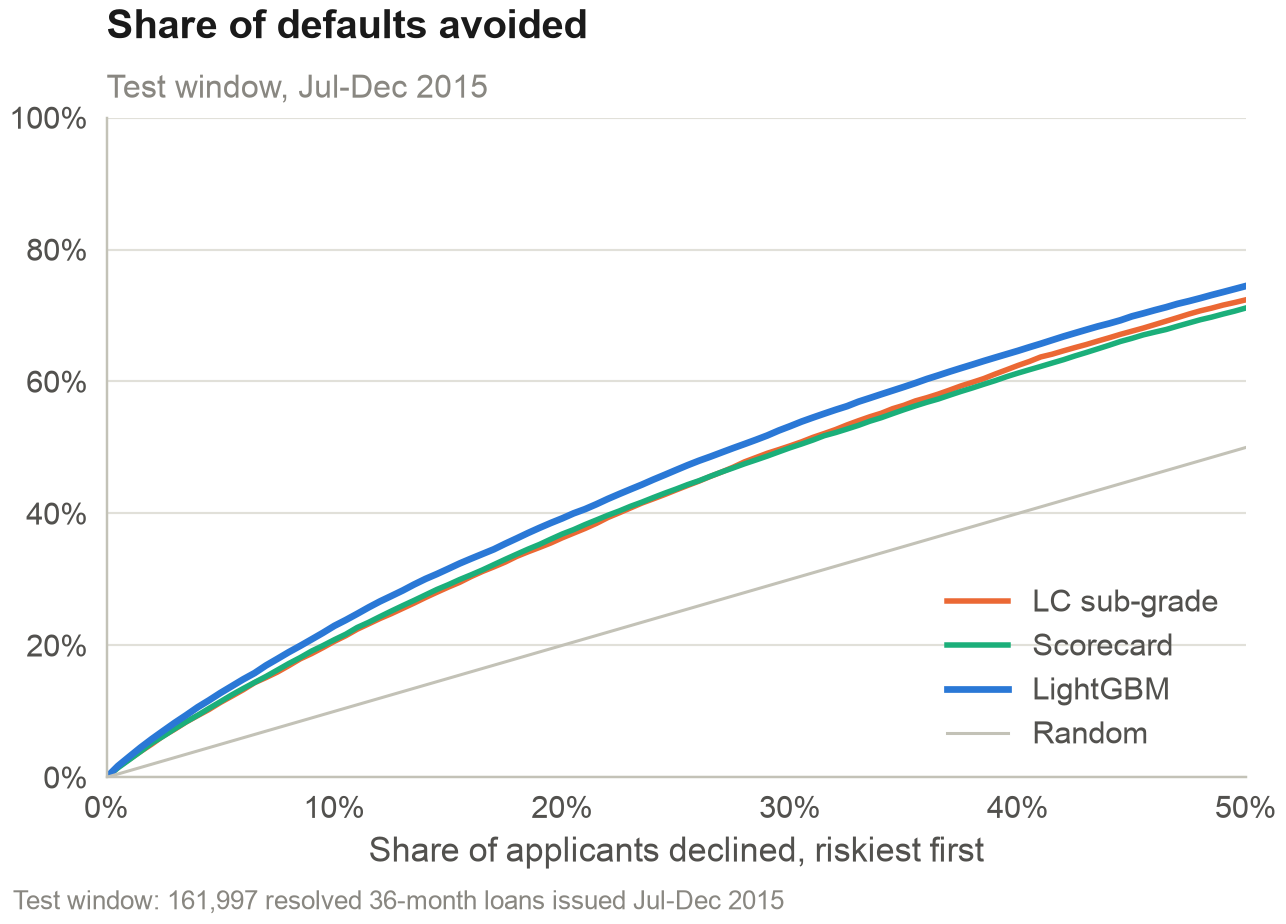

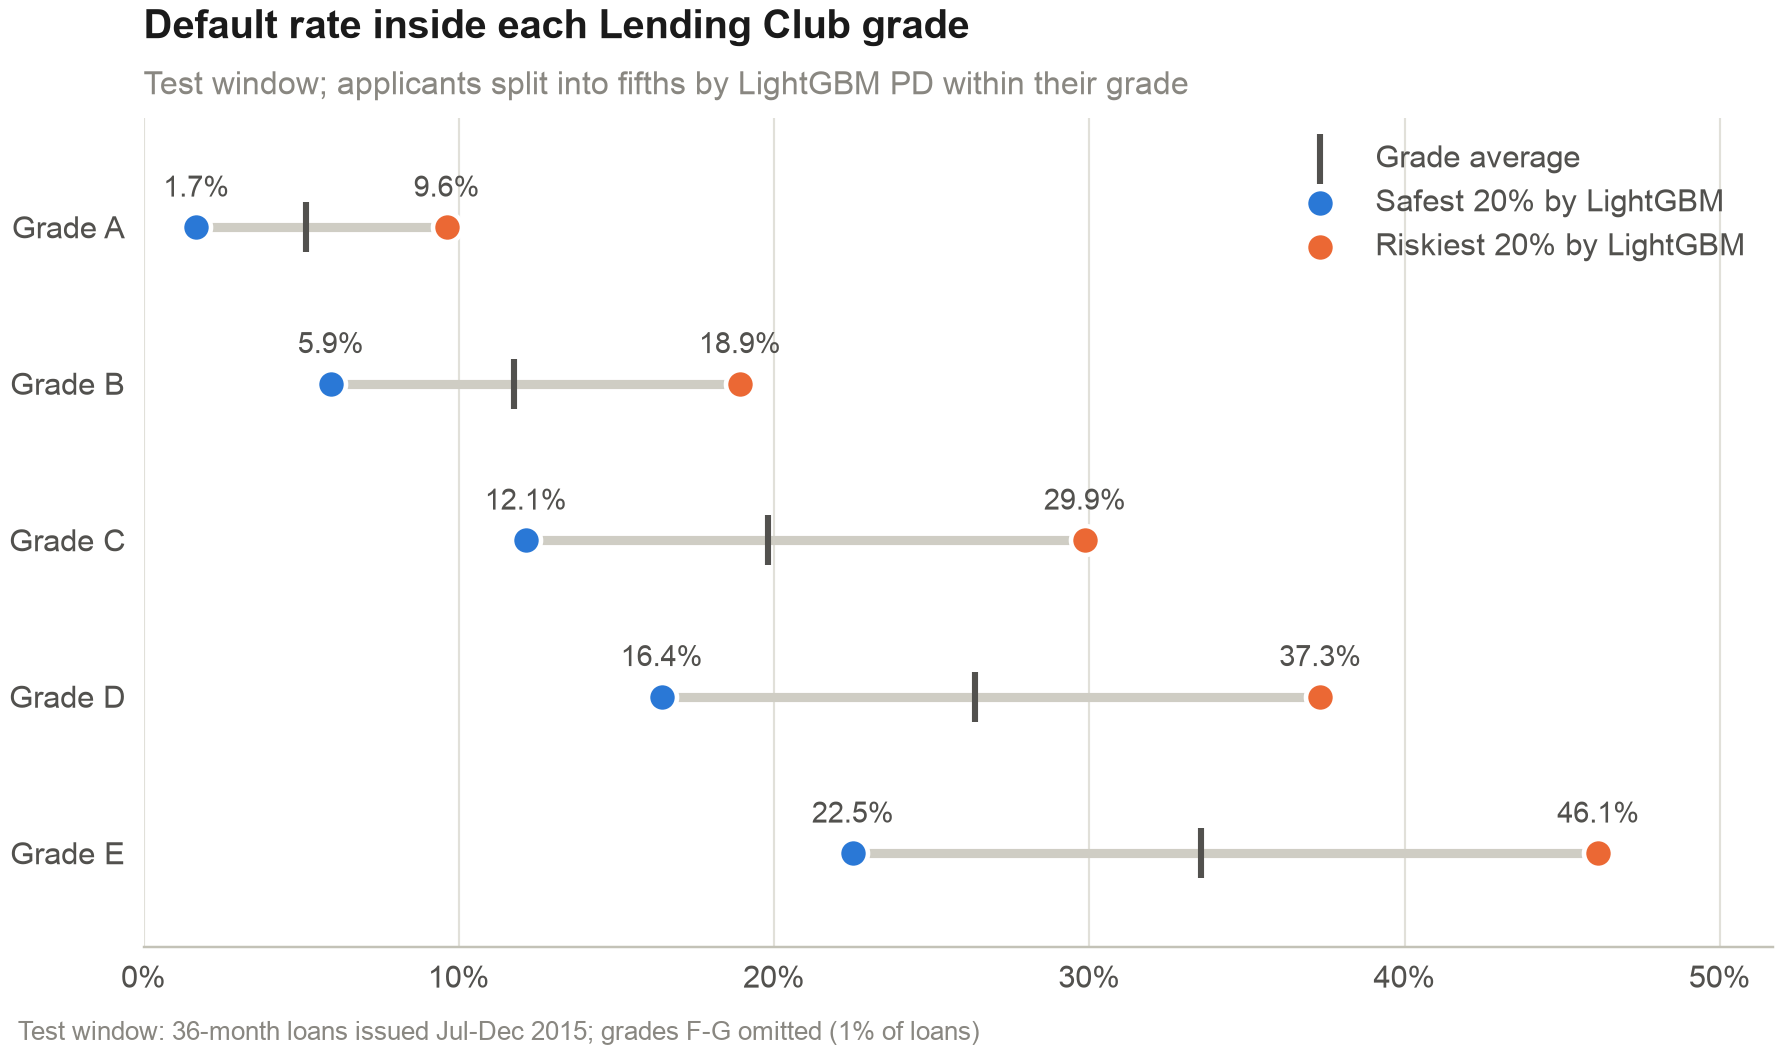

In [4]:
fig("default_capture_curve", 600)
fig("within_grade_spread")

MD The ranking gain over the grade is modest overall, but inside each grade the model separates loans whose default rates differ by a factor of two or more.

## 3. Global drivers (SHAP)

In [5]:
pd.read_csv(C.TABLES / "shap_importance.csv").head(12)

,feature,label,mean_abs_shap
0,fico,FICO score at application,0.1974
1,loan_to_income,Loan amount / annual income,0.1363
2,acc_open_past_24mths,"Accounts opened, last 24 months",0.1339
3,dti,Debt-to-income ratio (%),0.1322
4,annual_inc,Annual income,0.0963
5,percent_bc_gt_75,Share of bankcards above 75% of limit (%),0.0826
6,purpose,Loan purpose,0.0805
7,num_tl_op_past_12m,"Accounts opened, last 12 months",0.0805
8,home_ownership,Home ownership,0.0786
9,mths_since_recent_bc,Months since newest bankcard,0.0697


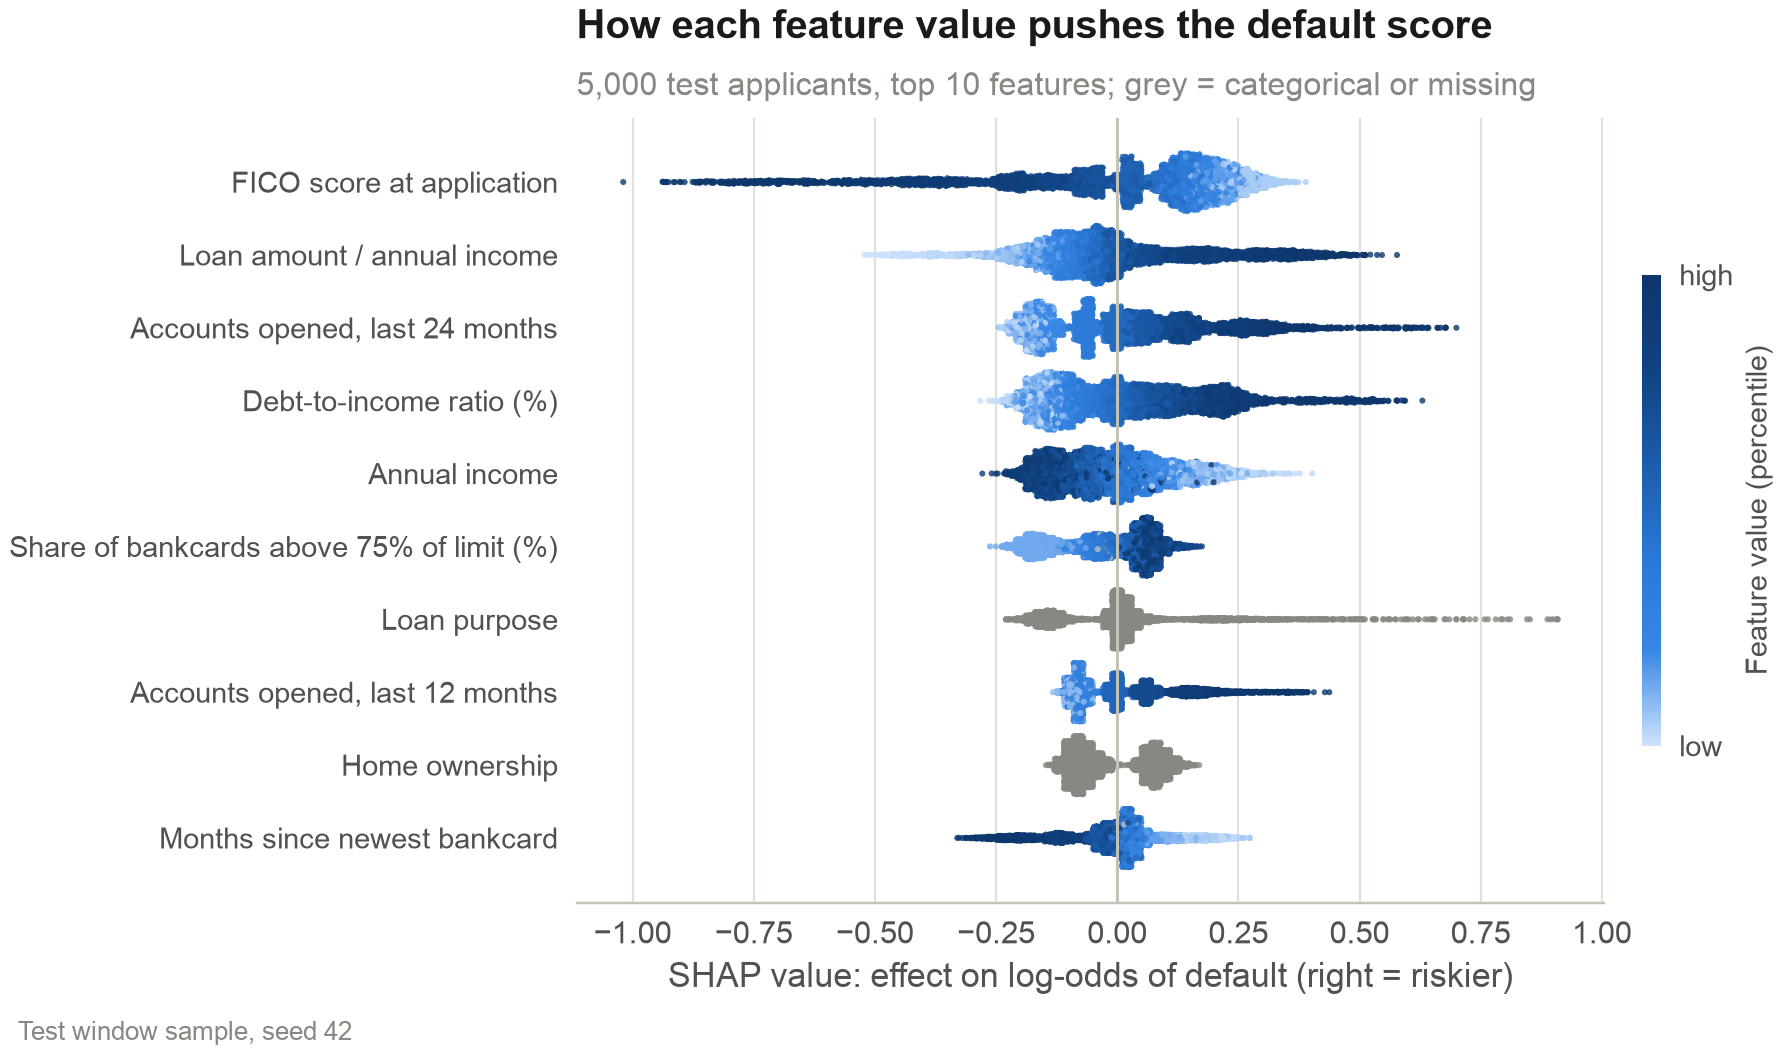

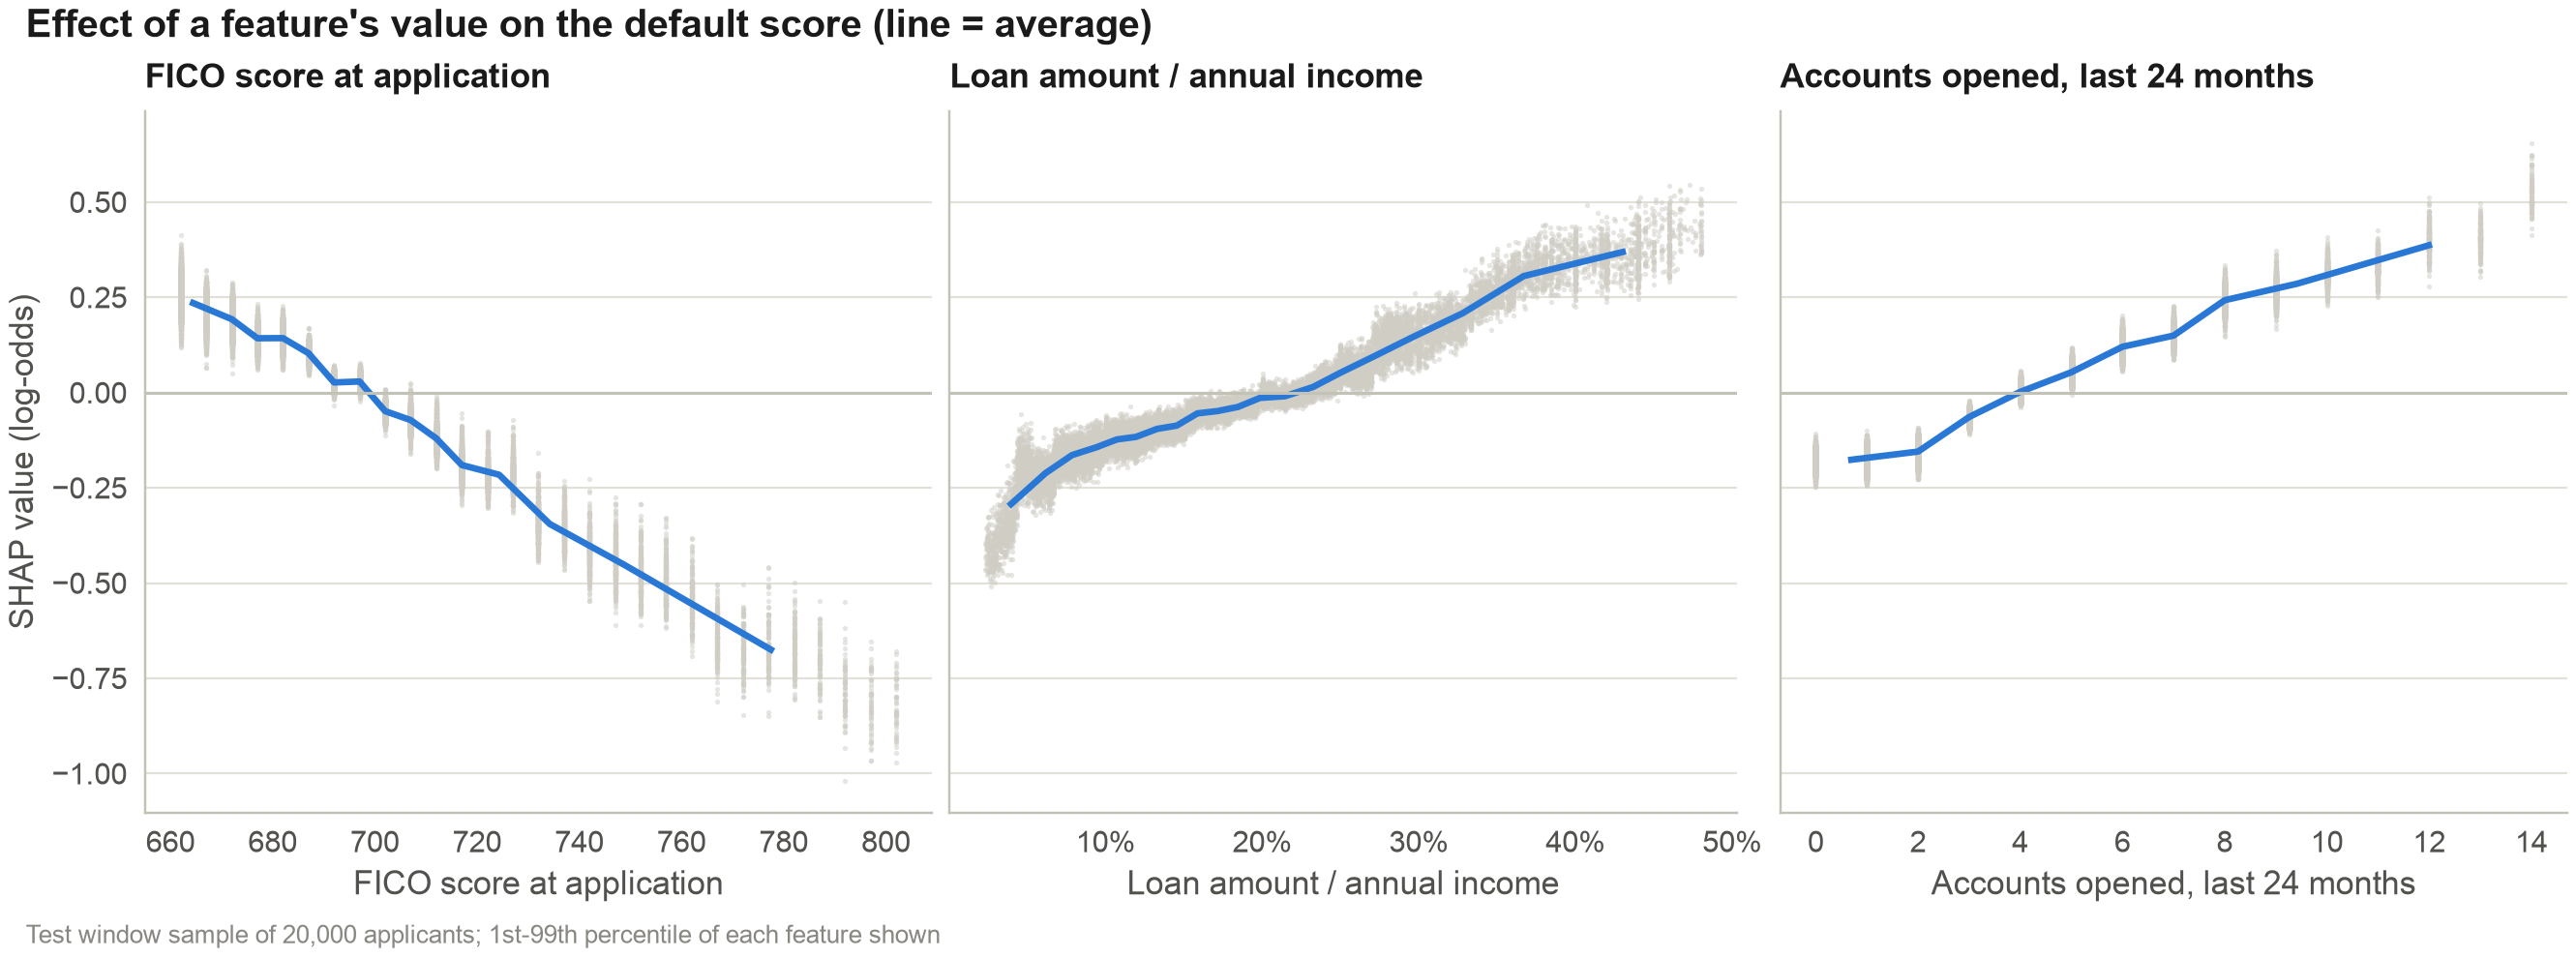

In [6]:
fig("shap_beeswarm")
fig("shap_dependence")

MD## 4. One applicant, in plain English

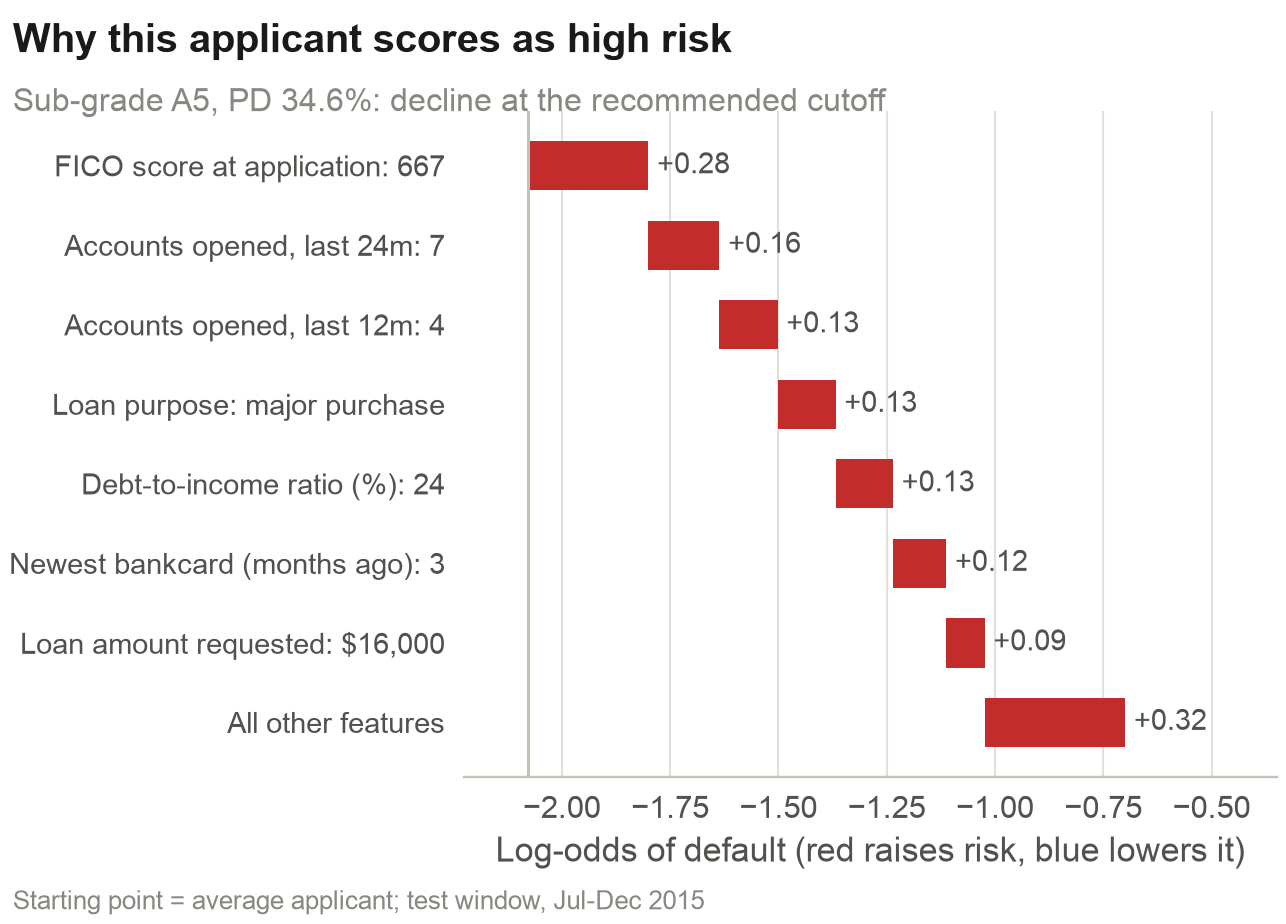

Sub-grade A5, PD 34.6%, decision: decline
Main reasons:
 - FICO score of 667 (median applicant 692)
 - 7 credit accounts opened in the last 24 months (median 4)
 - 4 credit accounts opened in the last 12 months (median 2)


In [7]:
fig("shap_waterfall_declined", 600)
ex = m["shap"]["examples"]["declined"]
print(f"Sub-grade {ex['grade']}, PD {ex['pd']:.1%}, decision: {ex['decision']}")
print("Main reasons:")
for r in ex["reasons"]:
    print(" -", r)

In [8]:
rc = json.loads((C.APP_DATA / "reason_codes.json").read_text())
pd.DataFrame([{"applicant": a["applicant"], "pd": a["pd"], "decision": a["decision"], "reason 1": a["reasons"][0] if a["reasons"] else ""}
              for a in rc["applicants"][-5:]])

,applicant,pd,decision,reason 1
0,Applicant 196,0.4638,decline,Debt-to-income ratio of 37% (median 17%)
1,Applicant 197,0.4742,decline,Loan equal to 45% of annual income (median 18%)
2,Applicant 198,0.4747,decline,10 credit accounts opened in the last 24 month...
3,Applicant 199,0.5775,decline,13 credit accounts opened in the last 24 month...
4,Applicant 200,0.5786,decline,15 credit accounts opened in the last 24 month...


MD**Answer.** LightGBM ranks risk better than the sub-grade on loans it never saw, stays calibrated after recalibration, and every decision comes with reasons a credit officer can read. These reason codes feed the simulator's applicant tab.